In [1]:
import pandas as pd
df = pd.read_csv(
    r"C:\Users\Manoj\OneDrive\Attachments\Desktop\mongo project\ai-impact-jobs-layoff-risk-dataset.csv"
)
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nData types:")
print(df.dtypes)
print("\nLayoff risk distribution:")
print(df["Layoff_Risk"].value_counts())
print("\nUnique layoff-risk categories:")
print(df["Layoff_Risk"].unique())
categorical_cols = df.select_dtypes(
    include="object"
).columns
for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())


Dataset shape: (20000, 16)

Columns: ['Age', 'Education_Level', 'Years_of_Experience', 'Industry', 'Job_Role', 'Company_Size', 'Job_Level', 'Routine_Task_Percentage', 'Creativity_Requirement', 'Human_Interaction_Level', 'AI_Adoption_Level', 'Number_of_AI_Tools_Used', 'AI_Usage_Hours_Per_Week', 'Tasks_Automated_Percentage', 'AI_Training_Hours', 'Layoff_Risk']

First 5 rows:


,Age,Education_Level,Years_of_Experience,Industry,Job_Role,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,Tasks_Automated_Percentage,AI_Training_Hours,Layoff_Risk
0,59,Master's,6,Finance,Accountant,Medium,Entry,84,21,94,Medium,5,7,40,26,High
1,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30,84,68,Low,2,2,14,9,Low
2,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12,86,71,Low,0,1,6,3,Low
3,27,Bachelor's,6,Finance,Auditor,Large,Entry,90,18,21,Medium,3,10,67,26,High
4,49,High School,12,Finance,Auditor,Small,Entry,49,52,72,Medium,5,13,26,19,Medium



Missing values:
Age                           0
Education_Level               0
Years_of_Experience           0
Industry                      0
Job_Role                      0
Company_Size                  0
Job_Level                     0
Routine_Task_Percentage       0
Creativity_Requirement        0
Human_Interaction_Level       0
AI_Adoption_Level             0
Number_of_AI_Tools_Used       0
AI_Usage_Hours_Per_Week       0
Tasks_Automated_Percentage    0
AI_Training_Hours             0
Layoff_Risk                   0
dtype: int64

Duplicate rows: 0

Data types:
Age                            int64
Education_Level               object
Years_of_Experience            int64
Industry                      object
Job_Role                      object
Company_Size                  object
Job_Level                     object
Routine_Task_Percentage        int64
Creativity_Requirement         int64
Human_Interaction_Level        int64
AI_Adoption_Level             object
Number_of_AI_Tools_

In [2]:
import json
df.to_json(
    "employment_data.json",
    orient="records",
    indent=2,
    force_ascii=False
)
print("JSON file created successfully!")
print("Total records:", len(df))


JSON file created successfully!
Total records: 20000


In [3]:
from pymongo import MongoClient
client = MongoClient("mongodb://localhost:27017/")
print(client.admin.command("ping"))
db = client["AI_Impact_Jobs"]
collection = db["employment_records"]
records = df.to_dict("records")
result = collection.insert_many(records)
print("Inserted records:", len(result.inserted_ids))
print("Total documents in MongoDB:", collection.count_documents({}))
print("\nOne document:")
print(collection.find_one())
print("\nFirst 5 records:")
for record in collection.find().limit(5):
    print(record)


{'ok': 1.0}
Inserted records: 20000
Total documents in MongoDB: 40000

One document:
{'_id': ObjectId('6ae36980b38bb3cb8ea941db'), 'Age': 59, 'Education_Level': "Master's", 'Years_of_Experience': 6, 'Industry': 'Finance', 'Job_Role': 'Accountant', 'Company_Size': 'Medium', 'Job_Level': 'Entry', 'Routine_Task_Percentage': 84, 'Creativity_Requirement': 21, 'Human_Interaction_Level': 94, 'AI_Adoption_Level': 'Medium', 'Number_of_AI_Tools_Used': 5, 'AI_Usage_Hours_Per_Week': 7, 'Tasks_Automated_Percentage': 40, 'AI_Training_Hours': 26, 'Layoff_Risk': 'High'}

First 5 records:
{'_id': ObjectId('6ae36980b38bb3cb8ea941db'), 'Age': 59, 'Education_Level': "Master's", 'Years_of_Experience': 6, 'Industry': 'Finance', 'Job_Role': 'Accountant', 'Company_Size': 'Medium', 'Job_Level': 'Entry', 'Routine_Task_Percentage': 84, 'Creativity_Requirement': 21, 'Human_Interaction_Level': 94, 'AI_Adoption_Level': 'Medium', 'Number_of_AI_Tools_Used': 5, 'AI_Usage_Hours_Per_Week': 7, 'Tasks_Automated_Percentage

In [4]:
from bson import ObjectId

test_record = {
    "Age": 25,
    "Education_Level": "Bachelor's",
    "Years_of_Experience": 2,
    "Industry": "IT",
    "Job_Role": "Data Analyst",
    "Company_Size": "Small",
    "Job_Level": "Entry",
    "Routine_Task_Percentage": 30,
    "Creativity_Requirement": 80,
    "Human_Interaction_Level": 60,
    "AI_Adoption_Level": "Medium",
    "Number_of_AI_Tools_Used": 2,
    "AI_Usage_Hours_Per_Week": 5,
    "Tasks_Automated_Percentage": 20,
    "AI_Training_Hours": 10,
    "Layoff_Risk": "Low"
}

result = collection.insert_one(test_record)
record_id = result.inserted_id
print("CREATE - Inserted ID:", record_id)
record = collection.find_one({"_id": record_id})
print("\nREAD - Retrieved record:")
print(record)
result = collection.update_one(
    {"_id": record_id},
    {"$set": {"AI_Training_Hours": 20}}
)
print("\nUPDATE - Matched:", result.matched_count)
print("UPDATE - Modified:", result.modified_count)
print(collection.find_one({"_id": record_id}))
result = collection.delete_one({"_id": record_id})
print("\nDELETE - Deleted records:", result.deleted_count)
print(collection.find_one({"_id": record_id}))


CREATE - Inserted ID: 6ae3755339fad6e1dd861076

READ - Retrieved record:
{'_id': ObjectId('6ae3755339fad6e1dd861076'), 'Age': 25, 'Education_Level': "Bachelor's", 'Years_of_Experience': 2, 'Industry': 'IT', 'Job_Role': 'Data Analyst', 'Company_Size': 'Small', 'Job_Level': 'Entry', 'Routine_Task_Percentage': 30, 'Creativity_Requirement': 80, 'Human_Interaction_Level': 60, 'AI_Adoption_Level': 'Medium', 'Number_of_AI_Tools_Used': 2, 'AI_Usage_Hours_Per_Week': 5, 'Tasks_Automated_Percentage': 20, 'AI_Training_Hours': 10, 'Layoff_Risk': 'Low'}

UPDATE - Matched: 1
UPDATE - Modified: 1
{'_id': ObjectId('6ae3755339fad6e1dd861076'), 'Age': 25, 'Education_Level': "Bachelor's", 'Years_of_Experience': 2, 'Industry': 'IT', 'Job_Role': 'Data Analyst', 'Company_Size': 'Small', 'Job_Level': 'Entry', 'Routine_Task_Percentage': 30, 'Creativity_Requirement': 80, 'Human_Interaction_Level': 60, 'AI_Adoption_Level': 'Medium', 'Number_of_AI_Tools_Used': 2, 'AI_Usage_Hours_Per_Week': 5, 'Tasks_Automated_Per

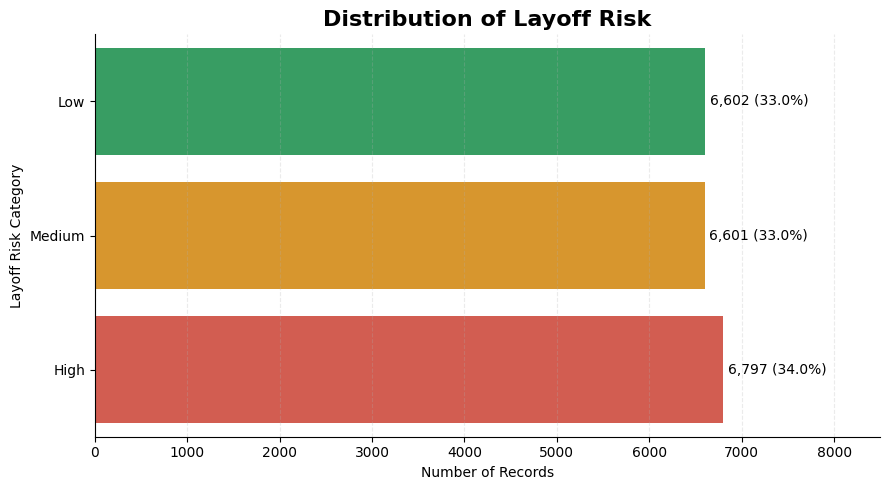

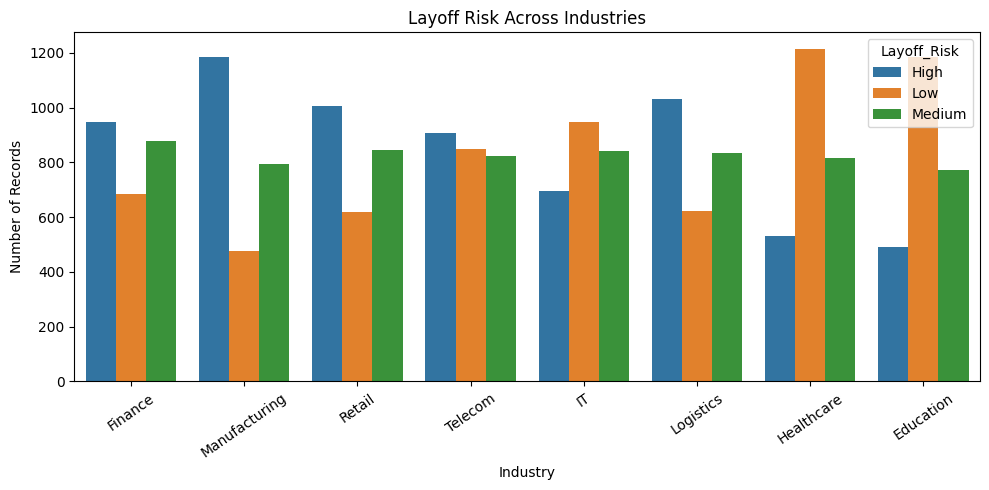

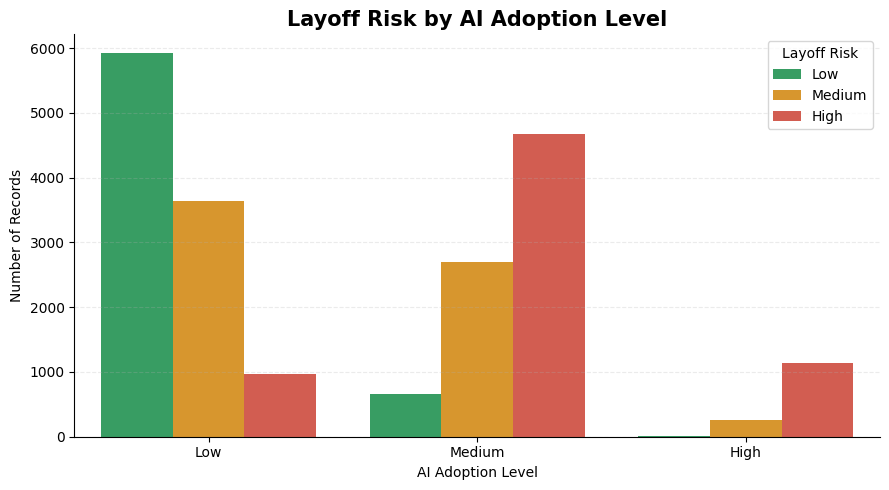

In [6]:
import os
os.makedirs("AI_Impact_Jobs_Project/outputs", exist_ok=True)

import matplotlib.pyplot as plt
import seaborn as sns

import matplotlib.pyplot as plt
import seaborn as sns

risk_counts = df["Layoff_Risk"].value_counts().reindex(
    ["Low", "Medium", "High"]
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=risk_counts.values,
    y=risk_counts.index,
    hue=risk_counts.index,
    palette={
        "Low": "#27AE60",
        "Medium": "#F39C12",
        "High": "#E74C3C"
    },
    legend=False
)

for i, value in enumerate(risk_counts.values):
    percentage = value / len(df) * 100
    ax.text(
        value + 50,
        i,
        f"{value:,} ({percentage:.1f}%)",
        va="center",
        fontsize=10
    )

plt.title("Distribution of Layoff Risk", fontsize=16, fontweight="bold")
plt.xlabel("Number of Records")
plt.ylabel("Layoff Risk Category")
plt.xlim(0, max(risk_counts.values) * 1.25)
plt.grid(axis="x", linestyle="--", alpha=0.25)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(
    "AI_Impact_Jobs_Project/outputs/layoff_risk_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Industry",
    hue="Layoff_Risk"
)

plt.title("Layoff Risk Across Industries")
plt.xlabel("Industry")
plt.ylabel("Number of Records")
plt.xticks(rotation=35)
plt.tight_layout()
plt.savefig(
    "AI_Impact_Jobs_Project/outputs/layoff_risk_by_industry.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="AI_Adoption_Level",
    hue="Layoff_Risk",
    order=["Low", "Medium", "High"],
    hue_order=["Low", "Medium", "High"],
    palette={
        "Low": "#27AE60",
        "Medium": "#F39C12",
        "High": "#E74C3C"
    }
)

plt.title("Layoff Risk by AI Adoption Level", fontsize=15, fontweight="bold")
plt.xlabel("AI Adoption Level")
plt.ylabel("Number of Records")
plt.legend(title="Layoff Risk")
plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(
    "AI_Impact_Jobs_Project/outputs/ai_adoption_vs_layoff_risk.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [7]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

X = df.drop(columns=["Layoff_Risk"])
y = df["Layoff_Risk"]

numeric_cols = X.select_dtypes(include="number").columns
categorical_cols = X.select_dtypes(include="object").columns

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_cols),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Features:", X.shape[1])
print("Target classes:", y.unique())

lr_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)

print("Logistic Regression trained successfully!")


Training records: 16000
Testing records: 4000
Features: 15
Target classes: ['High' 'Low' 'Medium']
Logistic Regression trained successfully!


In [8]:

from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

print("Random Forest trained successfully!")
print("Both models trained successfully!")


Random Forest trained successfully!
Both models trained successfully!


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9378,0.9377,0.9378,0.9377
1,Random Forest,0.9032,0.9032,0.9032,0.9032



Logistic Regression Report:
              precision    recall  f1-score   support

        High       0.95      0.96      0.96      1360
         Low       0.95      0.95      0.95      1320
      Medium       0.91      0.90      0.91      1320

    accuracy                           0.94      4000
   macro avg       0.94      0.94      0.94      4000
weighted avg       0.94      0.94      0.94      4000


Random Forest Report:
              precision    recall  f1-score   support

        High       0.93      0.93      0.93      1360
         Low       0.93      0.92      0.93      1320
      Medium       0.85      0.85      0.85      1320

    accuracy                           0.90      4000
   macro avg       0.90      0.90      0.90      4000
weighted avg       0.90      0.90      0.90      4000



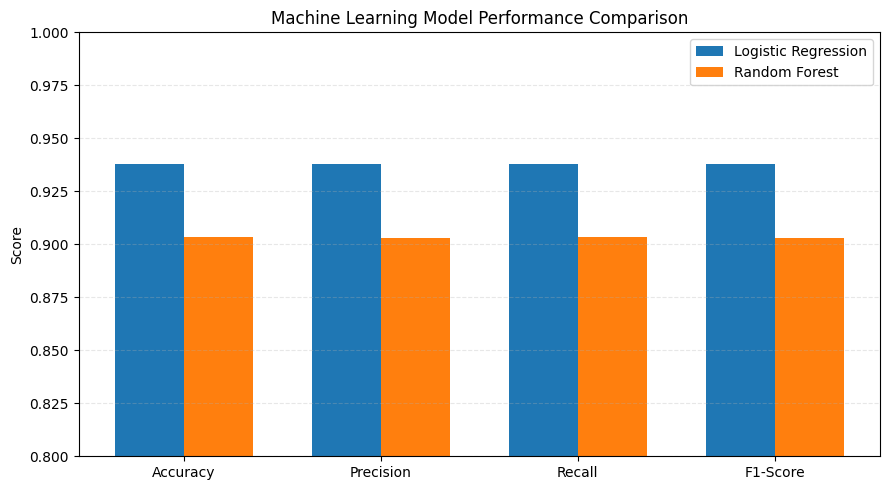

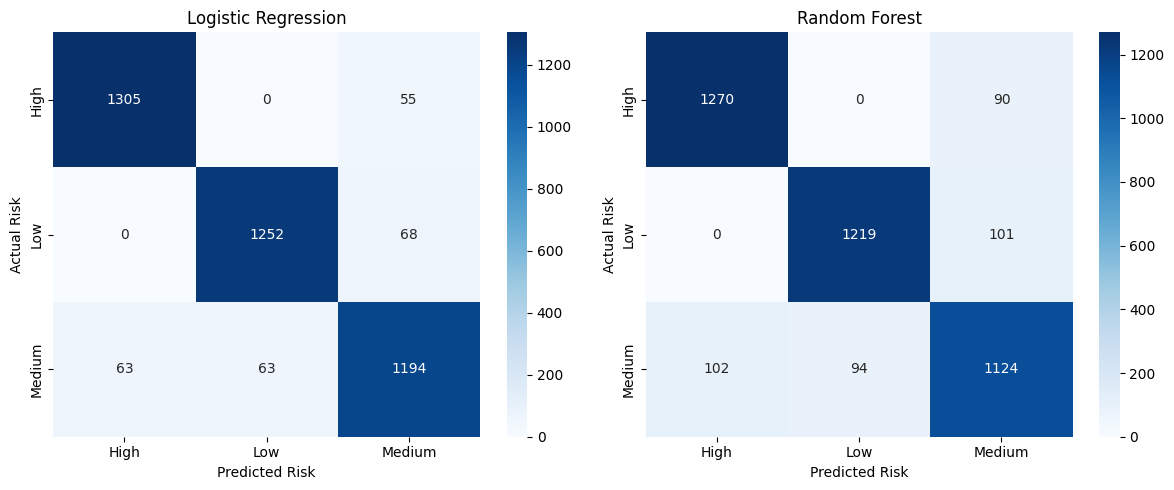

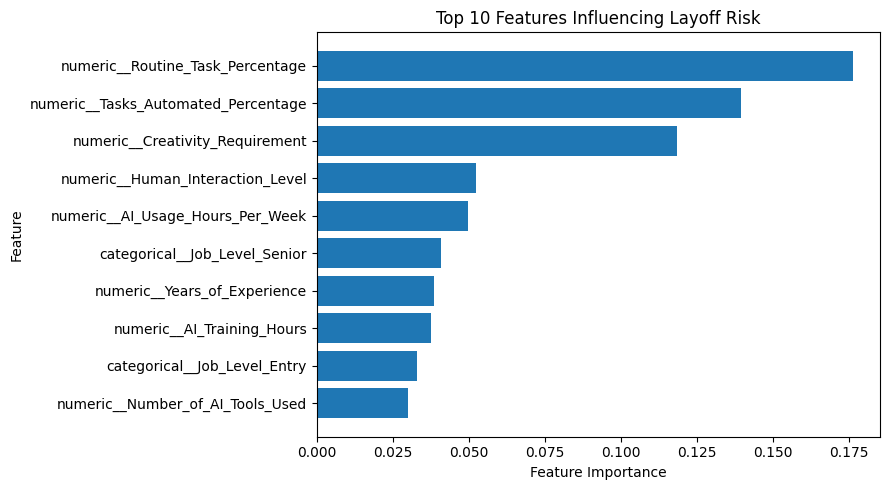

Dataset, metrics, graphs and models saved successfully!

Output files:
.ipynb_checkpoints
ai_adoption_vs_layoff_risk.png
confusion_matrices.png
evaluation_metrics.csv
feature_importance.csv
feature_importance.png
layoff_risk_by_industry.png
layoff_risk_distribution.png
logistic_regression_model.pkl
model_comparison.png
random_forest_model.pkl
your_graph_name.png


In [9]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

os.makedirs("AI_Impact_Jobs_Project/outputs", exist_ok=True)
os.makedirs("AI_Impact_Jobs_Project/dataset", exist_ok=True)

results = []

for name, predictions in [
    ("Logistic Regression", lr_predictions),
    ("Random Forest", rf_predictions)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="weighted"
        ),
        "Recall": recall_score(
            y_test, predictions, average="weighted"
        ),
        "F1-Score": f1_score(
            y_test, predictions, average="weighted"
        )
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

print("\nLogistic Regression Report:")
print(classification_report(y_test, lr_predictions))

print("\nRandom Forest Report:")
print(classification_report(y_test, rf_predictions))

results_df.to_csv(
    "AI_Impact_Jobs_Project/outputs/evaluation_metrics.csv",
    index=False
)

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
lr_scores = [
    accuracy_score(y_test, lr_predictions),
    precision_score(y_test, lr_predictions, average="weighted"),
    recall_score(y_test, lr_predictions, average="weighted"),
    f1_score(y_test, lr_predictions, average="weighted")
]
rf_scores = [
    accuracy_score(y_test, rf_predictions),
    precision_score(y_test, rf_predictions, average="weighted"),
    recall_score(y_test, rf_predictions, average="weighted"),
    f1_score(y_test, rf_predictions, average="weighted")
]

x = range(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    [i - width / 2 for i in x],
    lr_scores,
    width,
    label="Logistic Regression"
)

ax.bar(
    [i + width / 2 for i in x],
    rf_scores,
    width,
    label="Random Forest"
)

ax.set_xticks(list(x))
ax.set_xticklabels(metrics)
ax.set_ylim(0.80, 1.00)
ax.set_ylabel("Score")
ax.set_title("Machine Learning Model Performance Comparison")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "AI_Impact_Jobs_Project/outputs/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    ("Logistic Regression", lr_predictions),
    ("Random Forest", rf_predictions)
]

for ax, (name, predictions) in zip(axes, models):
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["High", "Low", "Medium"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["High", "Low", "Medium"],
        yticklabels=["High", "Low", "Medium"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Risk")
    ax.set_ylabel("Actual Risk")

plt.tight_layout()
plt.savefig(
    "AI_Impact_Jobs_Project/outputs/confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

preprocessor_fitted = rf_model.named_steps["preprocessing"]
classifier = rf_model.named_steps["classifier"]

feature_names = preprocessor_fitted.get_feature_names_out()
importance = classifier.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(
    by="Importance",
    ascending=False
).head(10)

plt.figure(figsize=(9, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.gca().invert_yaxis()
plt.title("Top 10 Features Influencing Layoff Risk")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    "AI_Impact_Jobs_Project/outputs/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

importance_df.to_csv(
    "AI_Impact_Jobs_Project/outputs/feature_importance.csv",
    index=False
)

df.to_csv(
    "AI_Impact_Jobs_Project/dataset/cleaned_employment_data.csv",
    index=False
)

df.to_json(
    "AI_Impact_Jobs_Project/dataset/employment_data.json",
    orient="records",
    indent=2
)

joblib.dump(
    lr_model,
    "AI_Impact_Jobs_Project/outputs/logistic_regression_model.pkl"
)

joblib.dump(
    rf_model,
    "AI_Impact_Jobs_Project/outputs/random_forest_model.pkl"
)

print("Dataset, metrics, graphs and models saved successfully!")

print("\nOutput files:")
for file in os.listdir("AI_Impact_Jobs_Project/outputs"):
    print(file)
